In [3]:
# ==============================================================================
# POLICE HEADQUARTERS DATA MANAGEMENT SYSTEM (PHDMS)
# VERTICAL (TOP-TO-BOTTOM) HIGH-RESOLUTION ER DIAGRAM GENERATOR
# ==============================================================================
# Architecture: 7 Sequential Vertical Tiers (Strict Up-to-Down Hierarchy)
# 15 Entities | 140+ Complete Attributes (Underlined PKs, FKs) | 25 Relationships
# Straight Connected Solid Lines (No Dotted Lines, No Horizontal Sprawl)
# ==============================================================================

import os
import graphviz

def generate_er_jpg():
    # Initialize Graphviz Digraph
    dot = graphviz.Digraph('Police_HQ_ER_Diagram', format='jpg')

    # Global Diagram Attributes - Optimized for Vertical (Top-to-Bottom) Aspect Ratio
    dot.attr(
        rankdir='TB',
        dpi='300',
        splines='polyline',   # Straight clean connected lines (no curve/dot distortion)
        overlap='false',
        compound='true',
        nodesep='0.5',        # Tight horizontal spacing between sibling nodes
        ranksep='0.8',        # Clean vertical spacing between successive tiers
        bgcolor='#FFFFFF'
    )
    dot.attr('node', fontname='Helvetica, Arial, sans-serif')
    dot.attr('edge', fontname='Helvetica, Arial, sans-serif', fontsize='10')

    # --------------------------------------------------------------------------
    # Complete Entity Attributes Dictionary (All 15 Database Tables)
    # --------------------------------------------------------------------------
    attributes = {
        "Police_Stations": [
            "<<u>id</u>> (PK)", "name", "location", "contact_details", 
            "is_deleted", "created_at", "updated_at"
        ],
        "Police_Officers": [
            "<<u>id</u>> (PK)", "badge_number", "first_name", "last_name", 
            "rank_title", "role", "station_id (FK)", "password_hash", 
            "email", "phone", "is_deleted", "created_at", "updated_at"
        ],
        "Criminals": [
            "<<u>id</u>> (PK)", "first_name", "last_name", "alias", 
            "dob", "gender", "physical_description", "mugshot_path", 
            "is_deleted", "created_at", "updated_at"
        ],
        "FIR": [
            "<<u>id</u>> (PK)", "fir_number", "station_id (FK)", "filed_by_officer_id (FK)", 
            "date_filed", "incident_date", "crime_type", "description", 
            "status", "latitude", "longitude", "is_deleted", "created_at", "updated_at"
        ],
        "Cases": [
            "<<u>id</u>> (PK)", "case_number", "fir_id (FK)", "assigned_officer_id (FK)", 
            "case_status", "priority", "open_date", "close_date", 
            "is_deleted", "created_at", "updated_at"
        ],
        "Case_Criminal_Junction": [
            "<<u>id</u>> (PK)", "case_id (FK)", "criminal_id (FK)", 
            "involvement_type", "notes", "created_at"
        ],
        "Evidences": [
            "<<u>id</u>> (PK)", "evidence_number", "case_id (FK)", "logged_by_officer_id (FK)", 
            "description", "evidence_type", "storage_location", "file_path", 
            "file_hash", "file_size_bytes", "mime_type", "is_deleted", "created_at", "updated_at"
        ],
        "Evidence_Chain_Of_Custody": [
            "<<u>id</u>> (PK)", "evidence_id (FK)", "transferred_from_officer_id (FK)", 
            "transferred_to_officer_id (FK)", "transfer_timestamp", "purpose", 
            "custody_location", "created_at"
        ],
        "Court_Dates": [
            "<<u>id</u>> (PK)", "case_id (FK)", "criminal_id (FK)", "hearing_date", 
            "court_name", "judge_name", "decision", "notes", "created_at", "updated_at"
        ],
        "Warrants": [
            "<<u>id</u>> (PK)", "warrant_number", "case_id (FK)", "suspect_id (FK)", 
            "issuing_judge", "warrant_type", "status", "issue_date", 
            "expiry_date", "execution_date", "created_at", "updated_at"
        ],
        "Victims_And_Witnesses": [
            "<<u>id</u>> (PK)", "case_id (FK)", "person_type", "name", 
            "contact_info", "statement", "is_protected", "created_at", "updated_at"
        ],
        "Arrests_And_Custody": [
            "<<u>id</u>> (PK)", "arrest_number", "case_id (FK)", "suspect_id (FK)", 
            "arresting_officer_id (FK)", "station_id (FK)", "booking_timestamp", 
            "holding_cell_number", "bail_status", "bail_amount", 
            "release_timestamp", "created_at", "updated_at"
        ],
        "Alerts": [
            "<<u>id</u>> (PK)", "case_id (FK)", "alert_message", "severity", 
            "is_read", "created_at"
        ],
        "Alert_Reads": [
            "<<u>id</u>> (PK)", "alert_id (FK)", "officer_id (FK)", "read_at"
        ],
        "Audit_Logs": [
            "<<u>id</u>> (PK)", "officer_id (FK)", "action", "target_table", 
            "record_id", "details", "timestamp"
        ]
    }

    # --------------------------------------------------------------------------
    # 7 Logical Vertical Tiers (Strict Top-to-Bottom Sequential Flow)
    # --------------------------------------------------------------------------
    tiers = [
        # Tier 0: Headquarters & Jurisdictions (Top Level)
        ["Police_Stations"],
        
        # Tier 1: Personnel & Precinct Administration
        ["Police_Officers", "Audit_Logs"],
        
        # Tier 2: Incident Intake & Initial Filings
        ["FIR"],
        
        # Tier 3: Core Central Department - Case & Offender Management
        ["Cases", "Criminals"],
        
        # Tier 4: Investigation Records, Evidences & Witnesses
        ["Case_Criminal_Junction", "Victims_And_Witnesses", "Evidences"],
        
        # Tier 5: Chain of Custody & Tactical Department Alerts
        ["Evidence_Chain_Of_Custody", "Alerts", "Alert_Reads"],
        
        # Tier 6: Legal Resolutions, Judicial Warrants & Custody (Bottom Level)
        ["Warrants", "Court_Dates", "Arrests_And_Custody"]
    ]

    # Vertical Guide Spine: Invisible high-weight vertical backbone to anchor Up-to-Down flow
    spine_anchors = [
        "Police_Stations", "Police_Officers", "FIR", 
        "Cases", "Evidences", "Evidence_Chain_Of_Custody", "Court_Dates"
    ]
    for i in range(len(spine_anchors) - 1):
        dot.edge(spine_anchors[i], spine_anchors[i+1], style='invis', weight='25')

    # --------------------------------------------------------------------------
    # Render Entities as Clean Structured Schema Cards
    # --------------------------------------------------------------------------
    for t_idx, tier_nodes in enumerate(tiers):
        with dot.subgraph(name=f'subgraph_tier_{t_idx}') as sg:
            sg.attr(rank='same')
            for ent in tier_nodes:
                is_junction = ent in ["Case_Criminal_Junction", "Alert_Reads"]
                header_bg = "#4A148C" if is_junction else "#0D47A1"  # Purple for junction, Deep Blue for main
                
                rows_html = ""
                for attr in attributes[ent]:
                    is_pk = "<<u>" in attr
                    is_fk = "(FK)" in attr
                    clean_name = attr.replace("<<u>", "").replace("</u>>", "").replace("(PK)", "").replace("(FK)", "").strip()
                    
                    if is_pk:
                        badge = '<font color="#D84315"><b>[PK]</b></font> '
                        row_bg = '#FFFDE7'  # Warm gold highlight for primary keys
                        label_text = f'<u><b>{clean_name}</b></u>'
                    elif is_fk:
                        badge = '<font color="#1565C0"><b>[FK]</b></font> '
                        row_bg = '#FFFFFF'
                        label_text = f'<i>{clean_name}</i>'
                    else:
                        badge = '&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;'
                        row_bg = '#FFFFFF'
                        label_text = clean_name
                    
                    rows_html += f'<tr><td align="left" bgcolor="{row_bg}" border="1" cellpadding="3"><font point-size="9">{badge}{label_text}</font></td></tr>'
                
                table_html = f'''<<table border="0" cellborder="0" cellspacing="0" cellpadding="0" bgcolor="#FFFFFF" style="rounded">
                    <tr><td bgcolor="{header_bg}" align="center" cellpadding="5" border="1"><font color="#FFFFFF" point-size="11"><b>{ent.replace('_', ' ')}</b></font></td></tr>
                    {rows_html}
                </table>>'''
                
                sg.node(ent, shape='none', label=table_html)

    # --------------------------------------------------------------------------
    # Relationships & Cardinalities with Solid Straight Connecting Lines
    # --------------------------------------------------------------------------
    relationships = [
        # (Entity 1, Relationship Diamond Name, Entity 2, Cardinality 1, Cardinality 2)
        ("Police_Stations", "Employs", "Police_Officers", "1", "N"),
        ("Police_Stations", "Receives", "FIR", "1", "N"),
        ("Police_Stations", "Accommodates", "Arrests_And_Custody", "1", "N"),
        ("Police_Officers", "Registers", "FIR", "1", "N"),
        ("Police_Officers", "Investigates", "Cases", "1", "N"),
        ("Police_Officers", "Catalogs", "Evidences", "1", "N"),
        ("Police_Officers", "Transfers_From", "Evidence_Chain_Of_Custody", "1", "N"),
        ("Police_Officers", "Transfers_To", "Evidence_Chain_Of_Custody", "1", "N"),
        ("Police_Officers", "Apprehends", "Arrests_And_Custody", "1", "N"),
        ("Police_Officers", "Acknowledges", "Alert_Reads", "1", "N"),
        ("Police_Officers", "Generates", "Audit_Logs", "1", "N"),
        ("FIR", "Converts_To", "Cases", "1", "1"),
        ("Cases", "Associates", "Case_Criminal_Junction", "1", "N"),
        ("Criminals", "Involved_In", "Case_Criminal_Junction", "1", "N"),
        ("Cases", "Contains", "Evidences", "1", "N"),
        ("Evidences", "Tracks_Custody", "Evidence_Chain_Of_Custody", "1", "N"),
        ("Cases", "Schedules", "Court_Dates", "1", "N"),
        ("Criminals", "Summoned_For", "Court_Dates", "1", "N"),
        ("Cases", "Generates_Warrant", "Warrants", "1", "N"),
        ("Criminals", "Subject_Of", "Warrants", "1", "N"),
        ("Cases", "Documents", "Victims_And_Witnesses", "1", "N"),
        ("Cases", "Results_In", "Arrests_And_Custody", "1", "N"),
        ("Criminals", "Detained_Under", "Arrests_And_Custody", "1", "N"),
        ("Cases", "Triggers", "Alerts", "1", "N"),
        ("Alerts", "Broadcast_To", "Alert_Reads", "1", "N")
    ]

    # Diamond Style for Relationships
    REL_STYLE = {
        'shape': 'diamond',
        'style': 'filled',
        'fillcolor': '#FFF3E0',   # Warm peach
        'color': '#E65100',       # Bold amber border
        'penwidth': '2.0',
        'fontsize': '9.5',
        'fontname': 'Helvetica-Bold',
        'margin': '0.12,0.06'
    }

    for e1, rel, e2, c1, c2 in relationships:
        rel_id = f"rel_{e1}_{rel}_{e2}"
        dot.node(rel_id, rel.replace('_', ' '), **REL_STYLE)
        
        # Solid straight line from Entity 1 to Diamond
        dot.edge(
            e1, rel_id, 
            label=f"  {c1}  ", 
            dir='none', 
            style='solid',
            color='#37474F', 
            penwidth='1.6',
            fontcolor='#B71C1C',  # Crimson red cardinalities
            fontsize='10',
            weight='3'
        )
        # Solid straight line from Diamond to Entity 2
        dot.edge(
            rel_id, e2, 
            label=f"  {c2}  ", 
            dir='none', 
            style='solid',
            color='#37474F', 
            penwidth='1.6',
            fontcolor='#B71C1C',  # Crimson red cardinalities
            fontsize='10',
            weight='3'
        )

    # Render High-Resolution JPG output
    output_filename = 'Police_HQ_ERD'
    dot.render(output_filename, cleanup=True)
    print(f"Successfully generated vertical top-to-bottom ER Diagram: '{output_filename}.jpg'")

if __name__ == "__main__":
    generate_er_jpg()


Successfully generated 'Police_HQ_ERD.jpg'


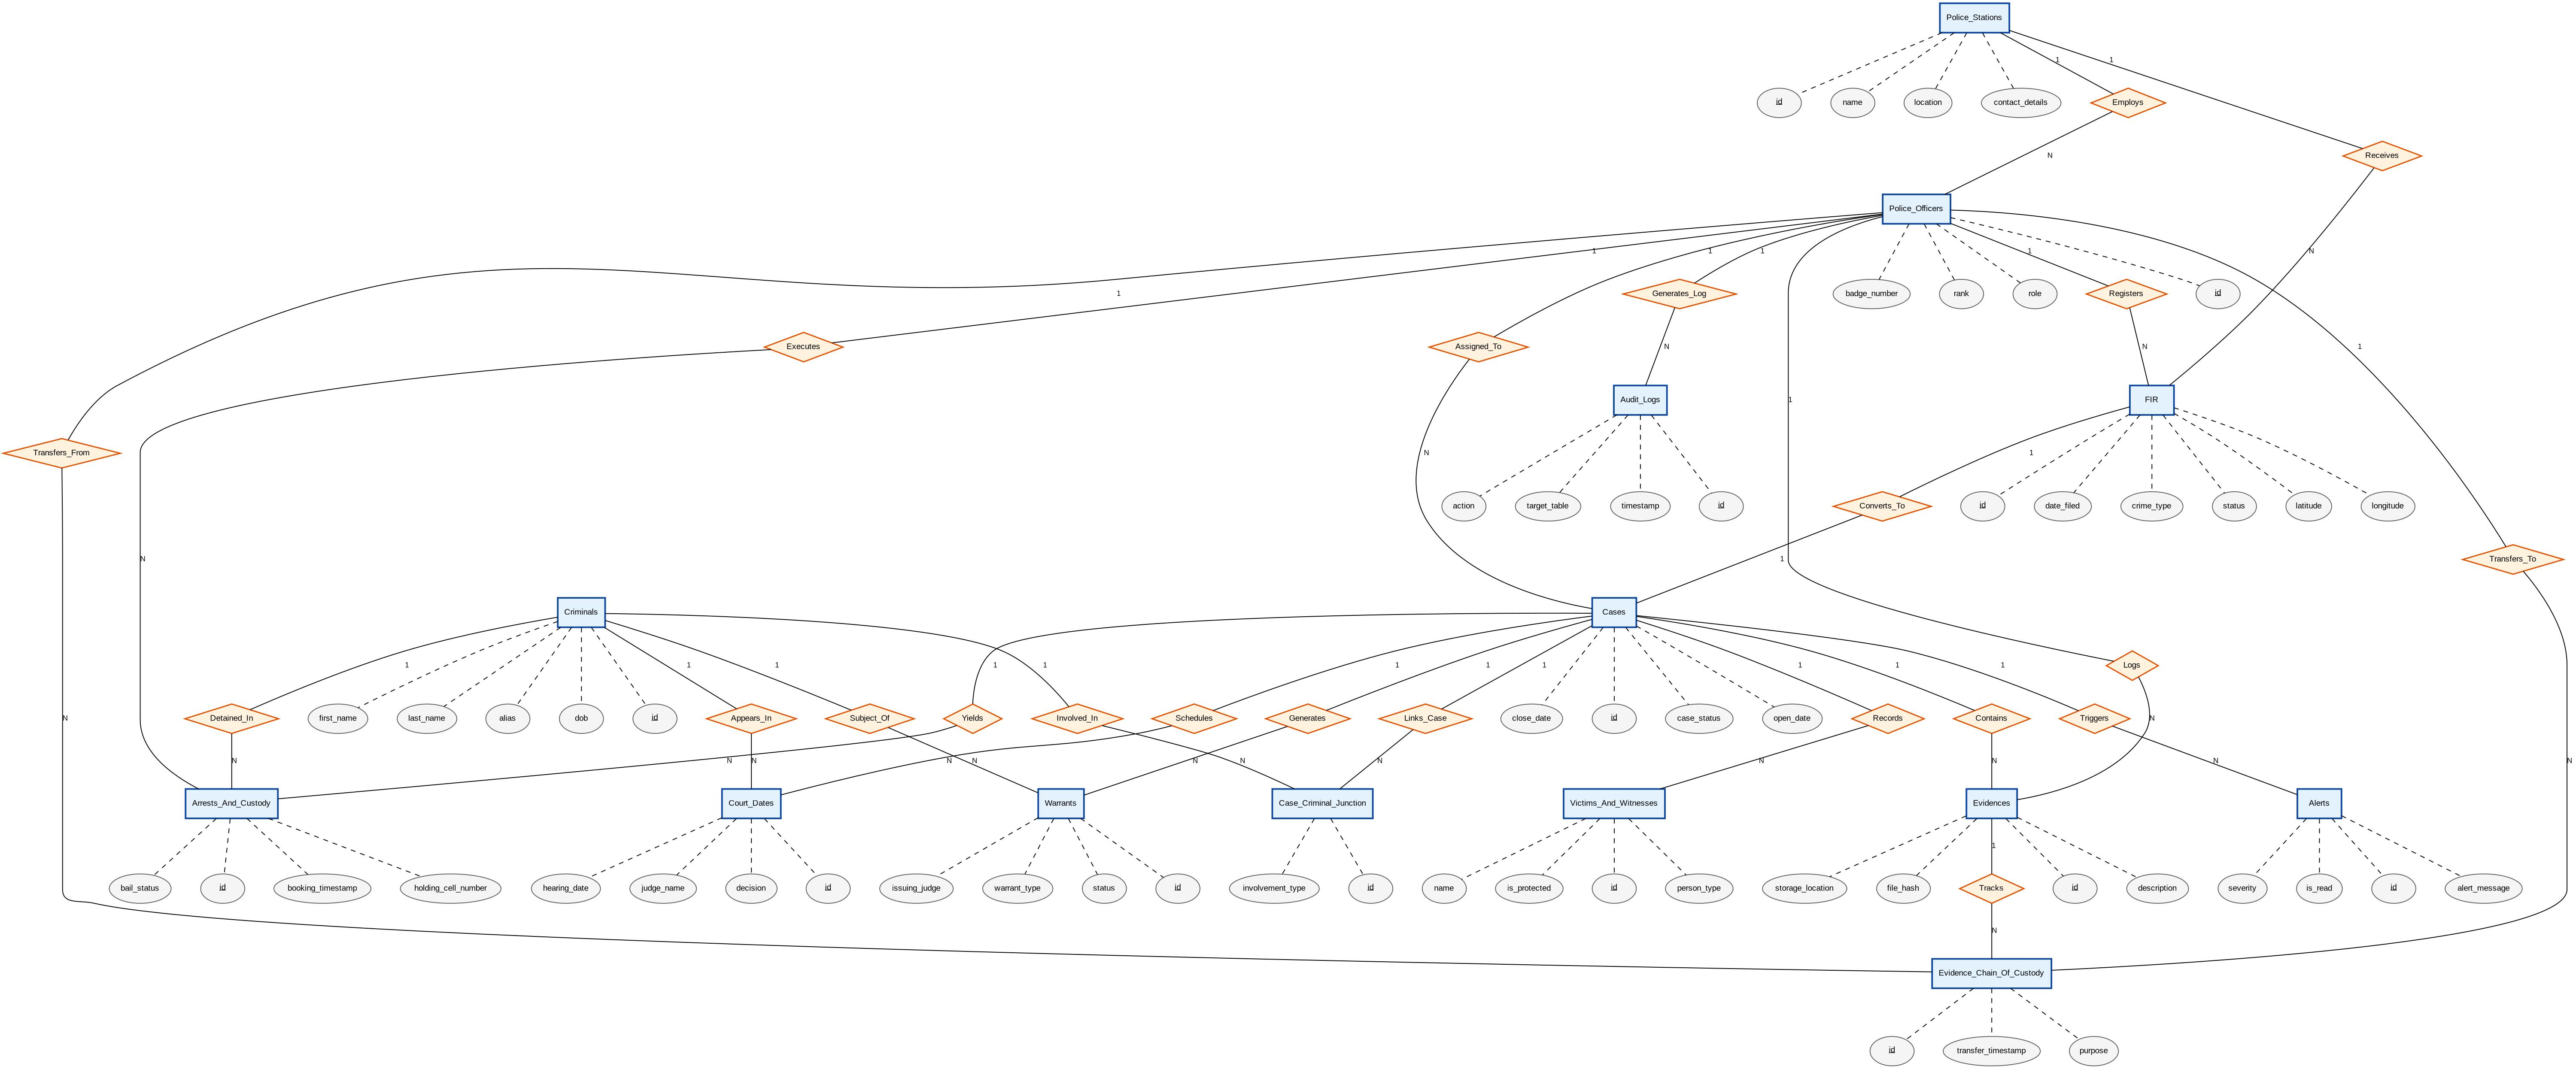

In [4]:
from IPython.display import Image, display

display(Image('Police_HQ_ERD.jpg'))

In [5]:
from google.colab import files

files.download('Police_HQ_ERD.jpg')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>